In [1]:

from google.colab import files

uploaded = files.upload()


Saving water_potability.csv to water_potability.csv


In [2]:

import pandas as pd

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (3276, 10)

Column names:
['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability']

First 5 rows:


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0



Missing values:
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64


In [3]:

# Check missing values before cleaning
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing values using the median
df = df.fillna(df.median(numeric_only=True))

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nDataset shape after cleaning:", df.shape)


Missing values before cleaning:
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

Missing values after cleaning:
ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64

Dataset shape after cleaning: (3276, 10)


In [4]:

X = df.drop("Potability", axis=1)
y = df["Potability"]

print("Features:", X.columns.tolist())
print("\nTarget classes:")
print(y.value_counts())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)


Features: ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']

Target classes:
Potability
0    1998
1    1278
Name: count, dtype: int64

Feature shape: (3276, 9)
Target shape: (3276,)


In [5]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 2620
Testing samples: 656


In [6]:

from sklearn.ensemble import RandomForestClassifier

# Create the model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [7]:

y_pred = rf_model.predict(X_test)

print("Actual values:", y_test.values[:10])
print("Predicted values:", y_pred[:10])


Actual values: [1 0 0 0 0 0 0 0 1 1]
Predicted values: [0 0 0 0 0 0 0 0 0 0]


In [8]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 67.07%

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.91      0.77       400
           1       0.68      0.29      0.41       256

    accuracy                           0.67       656
   macro avg       0.68      0.60      0.59       656
weighted avg       0.67      0.67      0.63       656


Confusion Matrix:
[[365  35]
 [181  75]]


In [9]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

dt_model = DecisionTreeClassifier(
    max_depth=10,
    class_weight="balanced",
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree Accuracy:",
      round(accuracy_score(y_test, dt_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, dt_pred, zero_division=0))


Decision Tree Accuracy: 60.52 %

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.75      0.70       400
           1       0.49      0.38      0.43       256

    accuracy                           0.61       656
   macro avg       0.57      0.57      0.56       656
weighted avg       0.59      0.61      0.59       656



In [10]:

import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, recall_score

comparison = pd.DataFrame({
    "Model": ["Random Forest", "Decision Tree"],
    "Accuracy (%)": [
        accuracy_score(y_test, y_pred) * 100,
        accuracy_score(y_test, dt_pred) * 100
    ],
    "Class 1 Recall (%)": [
        recall_score(y_test, y_pred, zero_division=0) * 100,
        recall_score(y_test, dt_pred, zero_division=0) * 100
    ],
    "Class 1 F1-score": [
        f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        f1_score(y_test, dt_pred, pos_label=1, zero_division=0)
    ]
})

display(comparison.round(2))


,Model,Accuracy (%),Class 1 Recall (%),Class 1 F1-score
0,Random Forest,67.07,29.30,0.41
1,Decision Tree,60.52,38.28,0.43


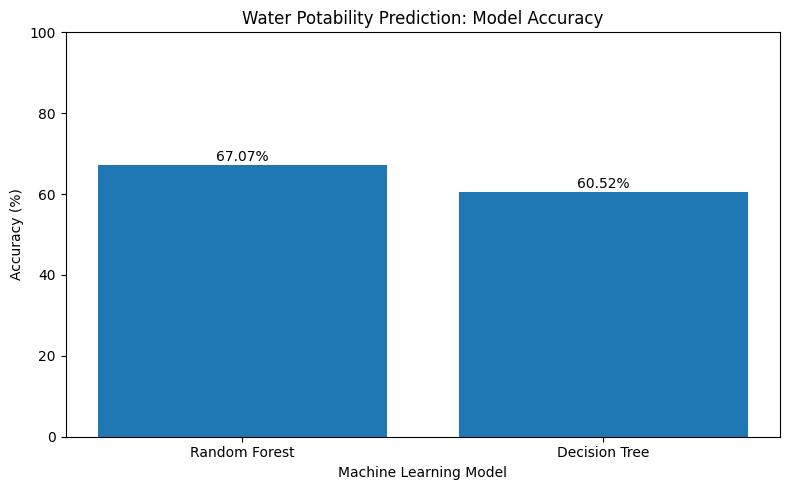

In [11]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["Accuracy (%)"]
)

plt.title("Water Potability Prediction: Model Accuracy")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(comparison["Accuracy (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()


,Feature,Importance
0,ph,0.129659
4,Sulfate,0.126579
1,Hardness,0.118491
3,Chloramines,0.117531
2,Solids,0.113358
5,Conductivity,0.101510
8,Turbidity,0.099174
6,Organic_carbon,0.096901
7,Trihalomethanes,0.096796


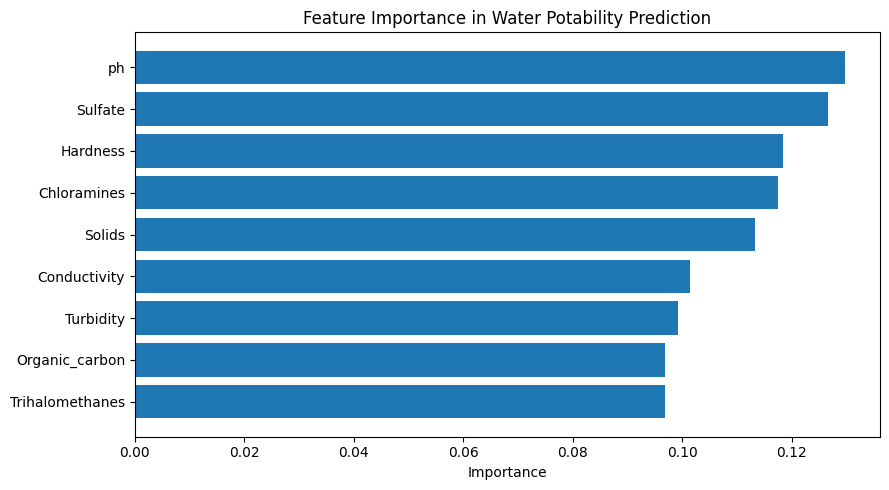

In [12]:

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

display(importance)

plt.figure(figsize=(9, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.gca().invert_yaxis()
plt.title("Feature Importance in Water Potability Prediction")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


In [13]:

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Get predicted probabilities for Class 1
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Try a lower threshold
threshold = 0.35
y_pred_tuned = (y_prob >= threshold).astype(int)

print("Threshold:", threshold)
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_tuned, zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))


Threshold: 0.35

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.53      0.61       400
           1       0.48      0.69      0.57       256

    accuracy                           0.59       656
   macro avg       0.61      0.61      0.59       656
weighted avg       0.63      0.59      0.60       656

Confusion Matrix:
[[213 187]
 [ 80 176]]


In [14]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for t in [0.30, 0.35, 0.40, 0.45, 0.50]:
    pred = (y_prob >= t).astype(int)

    results.append({
        "Threshold": t,
        "Accuracy (%)": accuracy_score(y_test, pred) * 100,
        "Class 1 Precision (%)": precision_score(
            y_test, pred, zero_division=0
        ) * 100,
        "Class 1 Recall (%)": recall_score(
            y_test, pred, zero_division=0
        ) * 100,
        "Class 1 F1-score": f1_score(
            y_test, pred, zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)
display(threshold_results.round(2))


,Threshold,Accuracy (%),Class 1 Precision (%),Class 1 Recall (%),Class 1 F1-score
0,0.30,52.74,44.23,80.86,0.57
1,0.35,59.30,48.48,68.75,0.57
2,0.40,63.11,52.67,53.91,0.53
3,0.45,65.09,57.46,40.62,0.48
4,0.50,66.77,66.67,29.69,0.41


In [15]:

import pandas as pd
print("Enter water-quality parameter values:")
sample = {}
for feature in X.columns:
    sample[feature] = float(
        input(f"Enter {feature}: ")
    )
sample_df = pd.DataFrame([sample], columns=X.columns)
prediction = rf_model.predict(sample_df)[0]
probabilities = rf_model.predict_proba(sample_df)[0]
print("\n--- Water Potability Prediction ---")
if prediction == 1:
    print("Predicted category: Potable (Class 1)")
else:
    print("Predicted category: Non-potable (Class 0)")

print(f"Model probability for Class 0: {probabilities[0]*100:.2f}%")
print(f"Model probability for Class 1: {probabilities[1]*100:.2f}%")

print("\nNote: This is a model prediction, not a drinking-water safety certification.")


Enter water-quality parameter values:
Enter ph: 7.0
Enter Hardness: 200
Enter Solids: 15000
Enter Chloramines: 7
Enter Sulfate: 300
Enter Conductivity: 400
Enter Organic_carbon: 10
Enter Trihalomethanes: 60
Enter Turbidity: 4

--- Water Potability Prediction ---
Predicted category: Non-potable (Class 0)
Model probability for Class 0: 77.50%
Model probability for Class 1: 22.50%

Note: This is a model prediction, not a drinking-water safety certification.


In [22]:

from sklearn.metrics import accuracy_score, recall_score, f1_score
import pandas as pd

final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Class 1 Recall",
        "Class 1 F1-score"
    ],
    "Random Forest": [
        round(accuracy_score(y_test, y_pred) * 100, 2),
        round(recall_score(y_test, y_pred, zero_division=0) * 100, 2),
        round(f1_score(y_test, y_pred, zero_division=0), 3)
    ],
    "Decision Tree": [
        round(accuracy_score(y_test, dt_pred) * 100, 2),
        round(recall_score(y_test, dt_pred, zero_division=0) * 100, 2),
        round(f1_score(y_test, dt_pred, zero_division=0), 3)
    ]
})

display(final_results)


,Metric,Random Forest,Decision Tree
0,Accuracy,67.07,60.520
1,Class 1 Recall,29.30,38.280
2,Class 1 F1-score,0.41,0.431
